In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta. La actividad I se va a subcontratar y la desviación típica de su duración depende del contratista elegido. El cliente exige terminar en 37 semanas con una probabilidad de al menos el 90 %.

In [3]:
pregunta_1 = "1. Determine la duración media del proyecto y la ruta crítica. ¿Está en ella la actividad subcontratada?  "
pregunta_2 = "2. Calcule la varianza del proyecto en función de la desviación típica σ de I.  "
pregunta_3 = "3. ¿Qué desviación típica máxima puede tener I para cumplir la exigencia del cliente?  "
pregunta_4 = "4. Si ningún contratista garantiza esa dispersión, ¿cuántas semanas habría que reducir la duración media del proyecto (manteniendo las varianzas) para cumplir con el contratista de σ = 1,5?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto y la ruta crítica. ¿Está en ella la actividad subcontratada?  

2. Calcule la varianza del proyecto en función de la desviación típica σ de I.  

3. ¿Qué desviación típica máxima puede tener I para cumplir la exigencia del cliente?  

4. Si ningún contratista garantiza esa dispersión, ¿cuántas semanas habría que reducir la duración media del proyecto (manteniendo las varianzas) para cumplir con el contratista de σ = 1,5?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado (σ de I por determinar)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 1       , 0.4               ),
    ('B'     , '---'      , 7       , 0.2               ),
    ('C'     , 'A,B'      , 7       , 0.1               ),
    ('D'     , 'C'        , 4       , 0.5               ),
    ('E'     , 'D'        , 4       , 0.6               ),
    ('F'     , 'D'        , 4       , 0.2               ),
    ('G'     , 'F'        , 4       , 0.8               ),
    ('H'     , 'E'        , 7       , 1                 ),
    ('I'     , 'H'        , 1       , np.nan               ),
    ('J'     , 'I'        , 5       , 0.3               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,1,0.4
B,---,7,0.2
C,"A,B",7,0.1
D,C,4,0.5
E,D,4,0.6
F,D,4,0.2
G,F,4,0.8
H,E,7,1.0
I,H,1,NaN


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
X, plazo, probabilidad_objetivo = 'I', 37, 0.9

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto y la ruta crítica. ¿Está en ella la actividad subcontratada?  

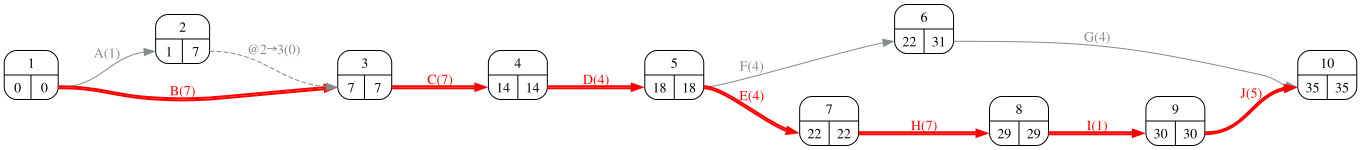

In [7]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [8]:
duracion_media = proyecto.duration(datos_proyecto['duration'])
criticas = sorted(set(a for acts in proyecto.critical_path(datos_proyecto['duration']).values() for a in acts))
Markdown(f'Duración media {duracion_media} semanas; ruta crítica {" - ".join(criticas)}. {X} {"sí" if X in criticas else "no"} está en ella.')

Duración media 35 semanas; ruta crítica B - C - D - E - H - I - J. I sí está en ella.

## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. Calcule la varianza del proyecto en función de la desviación típica σ de I.  

In [10]:
var_resto = float((datos_proyecto.loc[[a for a in criticas if a != X], 'standard_deviation'] ** 2).sum())
Markdown(f'Varianza del proyecto = varianza del resto de la ruta crítica + σ² = {var_resto:.3f} + σ².')

Varianza del proyecto = varianza del resto de la ruta crítica + σ² = 1.750 + σ².

## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. ¿Qué desviación típica máxima puede tener I para cumplir la exigencia del cliente?  

Se necesita $P(T \le plazo) \ge p$, es decir, $\dfrac{plazo - \mu}{\sigma_T} \ge z_p$, luego $\sigma_T \le \dfrac{plazo - \mu}{z_p}$ y $\sigma_X^2 \le \sigma_T^2 - \sigma_{resto}^2$.

In [12]:
z_p = norm.ppf(probabilidad_objetivo)
sigma_T_max = (plazo - duracion_media) / z_p
var_X_max = sigma_T_max ** 2 - var_resto
sigma_X_max = np.sqrt(var_X_max) if var_X_max > 0 else 0.0
Markdown(f'''σ_T ≤ ({plazo} − {duracion_media}) / {z_p:.3f} = {sigma_T_max:.3f}; σ_X² ≤ {sigma_T_max:.3f}² − {var_resto:.3f} = {var_X_max:.3f}, luego **σ_X ≤ {sigma_X_max:.2f} semanas**{" (ningún contratista vale: ni con σ = 0 se alcanza la probabilidad)" if var_X_max <= 0 else ""}.''')

σ_T ≤ (37 − 35) / 1.282 = 1.561; σ_X² ≤ 1.561² − 1.750 = 0.685, luego **σ_X ≤ 0.83 semanas**.

## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. Si ningún contratista garantiza esa dispersión, ¿cuántas semanas habría que reducir la duración media del proyecto (manteniendo las varianzas) para cumplir con el contratista de σ = 1,5?  

In [14]:
sigma_contratista = 1.5
sigma_T = np.sqrt(var_resto + sigma_contratista ** 2)
media_necesaria = plazo - z_p * sigma_T
reduccion = int(np.ceil(duracion_media - media_necesaria))
Markdown(f'Con σ_X = 1,5, σ_T = {sigma_T:.3f} y hace falta μ ≤ {plazo} − {z_p:.3f} × {sigma_T:.3f} = {media_necesaria:.2f}: '
         f'reducir la duración media en {max(reduccion, 0)} semana(s) (suponiendo que la ruta crítica no cambia al acortar).')

Con σ_X = 1,5, σ_T = 2.000 y hace falta μ ≤ 37 − 1.282 × 2.000 = 34.44: reducir la duración media en 1 semana(s) (suponiendo que la ruta crítica no cambia al acortar).